<a href="https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/04_duration_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · Duration EDA
**Goal:** understand what the duration data looks like *before* modeling. This is a large share of the "Dataset quality & EDA" and "Theoretical rigor" marks.

**Questions answered here**
1. How are phoneme durations distributed overall and per phoneme / class?
2. Which factors visibly change duration (stress, pauses, word position)?
3. **Theory test:** are real durations well described by an HMM's implicit duration model?
   - One HMM state with self-loop probability *a* gives a **geometric** duration (mode at 1 frame).
   - A phone with 3 left-to-right states is a sum of 3 geometrics, a **negative binomial** shifted by 3 (hump-shaped, minimum 3 frames).
   - We fit both with the same mean and compare log-likelihoods.

*Correction to my earlier explanation:* for a **single** state the geometric peaks at 1 frame; MFA's 3-state phones are already a negative binomial, which is more realistic. The remaining gap versus real durations is still the motivation for a learned duration model.

**Reads:** `phone_durations.csv.gz`, `alignment_qa.csv`. **Writes:** `results/04_*.csv/png/json`.

In [1]:
# ---- Cell 0: Setup (identical at the top of every notebook)
import os, sys, json, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
    IN_COLAB = True
except ImportError:                      # running somewhere else (local / tests)
    PROJECT_ROOT = os.environ.get('PROJECT_ROOT', os.getcwd())
    IN_COLAB = False
sys.path.insert(0, PROJECT_ROOT)
from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
A = cfg['audio']; P = cfg['abs_paths']
RAW, PROCESSED, ALIGN, SPLITS, RESULTS = P['raw'], P['processed'], P['alignments'], P['splits'], P['results']
for d in (PROCESSED, ALIGN, SPLITS, RESULTS):
    os.makedirs(d, exist_ok=True)
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Mounted at /content/drive
Project root: /content/drive/MyDrive/phonetic-tts | Colab: True


In [2]:
# ---- Write shared module: duration metrics
import os, importlib
_src = r'''"""Duration metrics. Durations are in mel frames (hop 256 @ 22,050 Hz = 11.61 ms per frame)."""
import numpy as np

FRAME_MS = 256 / 22050 * 1000


def summarize(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    err = p - y
    ss_res, ss_tot = (err ** 2).sum(), ((y - y.mean()) ** 2).sum()
    return {
        'mae_frames': float(np.abs(err).mean()),
        'mae_ms': float(np.abs(err).mean() * FRAME_MS),
        'rmse_frames': float(np.sqrt((err ** 2).mean())),
        'rmse_ms': float(np.sqrt((err ** 2).mean()) * FRAME_MS),
        'r2': float(1 - ss_res / ss_tot),
        'bias_frames': float(err.mean()),
        'n': int(len(y)),
    }
'''
_p = os.path.join(PROJECT_ROOT, "src/evaluation/metrics.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/evaluation/metrics.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/evaluation/metrics.py


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.features.phones import *
from src.evaluation.metrics import FRAME_MS
al = pd.read_csv(os.path.join(ALIGN, 'phone_durations.csv.gz'))
qa = pd.read_csv(os.path.join(ALIGN, 'alignment_qa.csv'))
ok = set(qa.loc[~qa.exclude, 'utt_id'])
al = al[al.utt_id.isin(ok)].sort_values(['utt_id', 'phone_idx']).reset_index(drop=True)
al['cls'] = al['base'].map(phone_class)
sp = al[~al.base.isin(['sil', 'spn'])].copy()
print('utterances kept:', len(ok), '| speech phones:', len(sp), '| silence intervals:', (al.base == 'sil').sum())

utterances kept: 11416 | speech phones: 777055 | silence intervals: 43627


## 1. Overall distribution

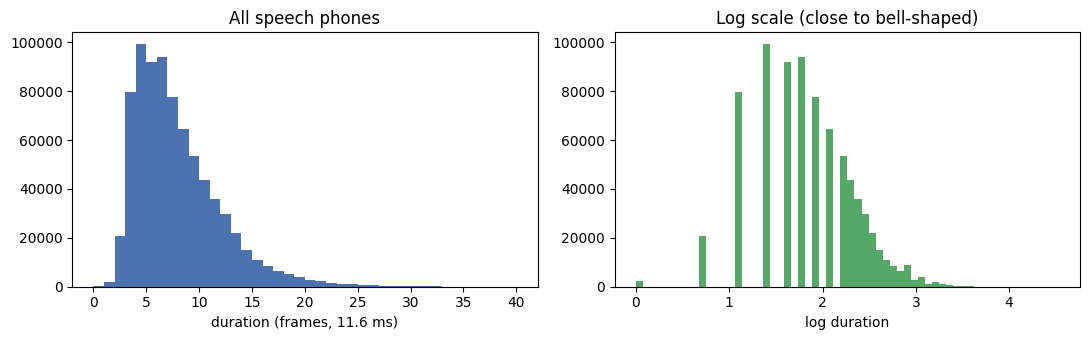

count    777055.000000
mean          7.456041
std           4.123979
min           0.000000
25%           4.000000
50%           7.000000
75%           9.000000
max          93.000000
Name: dur_f, dtype: float64
zero-frame phones: 293 | 1-frame phones: 1864


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(sp.dur_f.clip(upper=40), bins=np.arange(0, 41), color='#4c72b0'); ax[0].set_xlabel('duration (frames, 11.6 ms)'); ax[0].set_title('All speech phones')
ax[1].hist(np.log(sp.dur_f.clip(lower=1)), bins=60, color='#55a868'); ax[1].set_xlabel('log duration'); ax[1].set_title('Log scale (close to bell-shaped)')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, '04_overall_hist.png'), dpi=150); plt.show()
print(sp.dur_f.describe())
print('zero-frame phones:', (sp.dur_f <= 0).sum(), '| 1-frame phones:', (sp.dur_f == 1).sum())

**Observe:** durations are right-skewed (long tail), and `log(duration)` is much more symmetric. That is why the models later predict *log* duration (also what FastSpeech-style predictors do) and why the loss there is MSE in log space.

## 2. Per-phoneme statistics

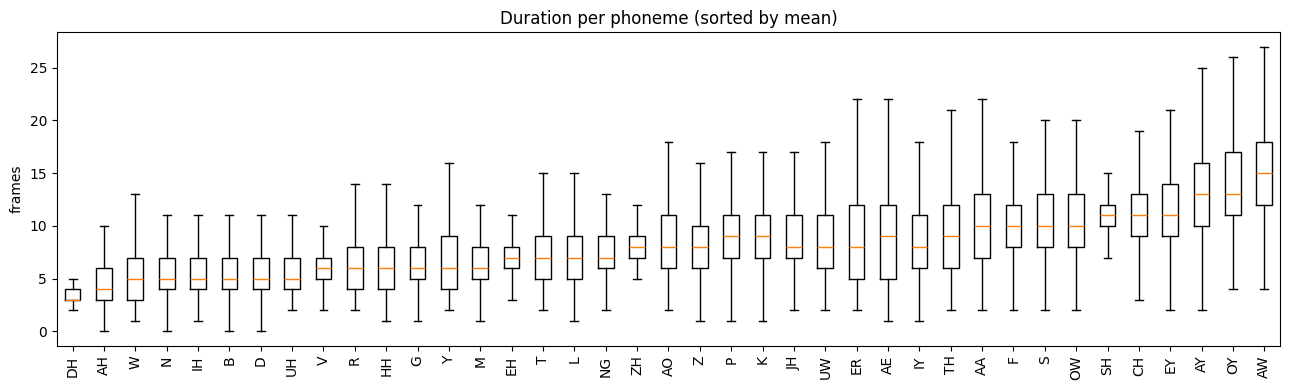

(      count  mean   std  median   p5   p95    cv        cls  mean_ms
 base                                                                
 DH    24717  3.67  1.38     3.0  2.0   6.0  0.38  fricative    42.60
 AH    85663  4.84  2.38     4.0  2.0   9.0  0.49      vowel    56.20
 W     17543  5.51  2.81     5.0  3.0  11.0  0.51      glide    64.00
 N     59176  5.60  2.80     5.0  3.0  11.0  0.50      nasal    65.02
 IH    49590  5.62  2.55     5.0  3.0  11.0  0.45      vowel    65.19
 B     13451  5.65  2.58     5.0  3.0  11.0  0.46       stop    65.59
 D     37327  5.82  2.77     5.0  3.0  11.0  0.48       stop    67.53
 UH     2543  5.87  3.08     5.0  3.0  13.0  0.52      vowel    68.18,
       count   mean   std  median   p5   p95    cv        cls  mean_ms
 base                                                                 
 S     37326  10.99  4.13    10.0  6.0  18.0  0.38  fricative   127.63
 OW     8684  11.25  4.73    10.0  6.0  21.0  0.42      vowel   130.62
 SH     6986  1

In [5]:
ps = sp.groupby('base').dur_f.agg(['count', 'mean', 'std', 'median', lambda s: s.quantile(.05), lambda s: s.quantile(.95)])
ps.columns = ['count', 'mean', 'std', 'median', 'p5', 'p95']
ps['cv'] = ps['std'] / ps['mean']; ps['cls'] = ps.index.map(phone_class); ps['mean_ms'] = ps['mean'] * FRAME_MS
ps = ps.sort_values('mean'); ps.to_csv(os.path.join(RESULTS, '04_phone_stats.csv'))
order = ps.index.tolist()
fig, ax = plt.subplots(figsize=(13, 4))
ax.boxplot([sp.loc[sp.base == p, 'dur_f'].clip(upper=40) for p in order], showfliers=False); ax.set_xticklabels(order)
ax.set_ylabel('frames'); ax.set_title('Duration per phoneme (sorted by mean)'); plt.xticks(rotation=90); plt.tight_layout()
plt.savefig(os.path.join(RESULTS, '04_per_phone_box.png'), dpi=150); plt.show()
ps.round(2).head(8), ps.round(2).tail(8)

In [6]:
cs = sp.groupby('cls').dur_f.agg(['count', 'mean', 'std', 'median']).sort_values('mean'); cs.to_csv(os.path.join(RESULTS, '04_class_stats.csv'))
cs.round(2)

,count,mean,std,median
cls,,,,
glide,21811,5.78,3.09,5.0
nasal,85838,6.07,2.95,5.0
liquid,62865,6.88,3.64,6.0
stop,154382,7.33,3.31,7.0
vowel,301394,7.69,4.66,6.0
fricative,142616,8.27,4.28,8.0
affricate,8149,10.39,4.28,10.0


**Observe / explain:** vowels are long and variable; stops are short (closure + burst). A predictor that knows only the phoneme identity already explains a lot of variance. The remaining variance (CV column) is what context features try to explain.

## 3. What else changes duration? (the features we will engineer)

In [7]:
# prepare helper flags using the full alignment (silences included)
g = al.groupby('utt_id')
al['next_is_sil'] = g['base'].shift(-1).eq('sil'); al['prev_is_sil'] = g['base'].shift(1).eq('sil')
sp = al[~al.base.isin(['sil', 'spn'])].copy()
wg = sp.groupby(['utt_id', 'word_idx'])
sp['word_len'] = wg['base'].transform('size'); sp['pos_in_word'] = wg.cumcount()
sp['is_word_last'] = sp['pos_in_word'] == sp['word_len'] - 1
rows = []
v = sp[sp.cls == 'vowel']
for s, d in v.groupby('stress'): rows.append(('vowel stress=%d' % s, d.dur_f.mean(), len(d)))
for flag, name in [('next_is_sil', 'followed by pause'), ('is_word_last', 'word-final'), ]:
    for val in (False, True): rows.append((f'{name}={val}', sp.loc[sp[flag] == val, 'dur_f'].mean(), int((sp[flag] == val).sum())))
effects = pd.DataFrame(rows, columns=['condition', 'mean_frames', 'n']); effects.to_csv(os.path.join(RESULTS, '04_effects.csv'), index=False)
effects.round(2)

,condition,mean_frames,n
0,vowel stress=0,5.81,140026
1,vowel stress=1,9.37,152150
2,vowel stress=2,8.74,9218
3,followed by pause=False,7.14,736829
4,followed by pause=True,13.28,40226
5,word-final=False,7.31,581979
6,word-final=True,7.90,195076


**Observe:** phones before a pause and word-final phones are longer (*phrase-final / word-final lengthening*), and stressed vowels are longer than unstressed ones. Each of these becomes a feature in notebook 05.

interior pauses: 28811 | median length (frames): 15.0


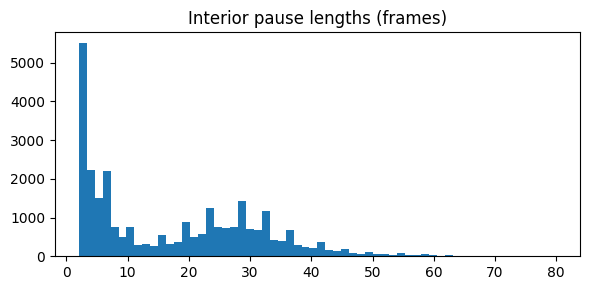

In [8]:
# interior pauses: silence between words (not leading/trailing)
sil = al[al.base == 'sil'].copy()
sil['interior'] = sil.groupby('utt_id').phone_idx.transform(lambda s: (s > s.min()) & (s < al.loc[s.index, 'phone_idx'].max()))
first_idx = al.groupby('utt_id').phone_idx.transform('min'); last_idx = al.groupby('utt_id').phone_idx.transform('max')
sil['interior'] = (sil.phone_idx > first_idx[sil.index]) & (sil.phone_idx < last_idx[sil.index])
print('interior pauses:', int(sil.interior.sum()), '| median length (frames):', sil.loc[sil.interior, 'dur_f'].median())
plt.figure(figsize=(6, 3)); plt.hist(sil.loc[sil.interior, 'dur_f'].clip(upper=80), bins=60); plt.title('Interior pause lengths (frames)'); plt.tight_layout()
plt.savefig(os.path.join(RESULTS, '04_pause_hist.png'), dpi=150); plt.show()

## 4. Theory test: geometric vs negative binomial vs real
For each frequent phoneme we match the mean, then compare the **average log-likelihood** of the real durations under each model (higher = better fit). Frames shorter than 3 are impossible under the 3-state negative binomial, so they get a tiny floor probability (and we count how many there are).

In [9]:
from scipy.stats import geom, nbinom
top = ps.sort_values('count', ascending=False).head(12).index
res = []
for p in top:
    d = sp.loc[sp.base == p, 'dur_f'].clip(lower=1).values; m = d.mean()
    ll_g = geom.logpmf(d, 1 / m).mean()
    pnb = min(3 / m, 0.999)
    ll_nb = np.log(np.maximum(np.where(d >= 3, nbinom.pmf(np.maximum(d - 3, 0), 3, pnb), 0), 1e-12)).mean()
    res.append(dict(phone=p, mean=m, ll_geometric=ll_g, ll_negbin3=ll_nb, frac_below_3=(d < 3).mean()))
fit = pd.DataFrame(res).round(3); fit.to_csv(os.path.join(RESULTS, '04_fit_loglik.csv'), index=False); fit

,phone,mean,ll_geometric,ll_negbin3,frac_below_3
0,AH,4.843,-2.466,-3.937,0.078
1,N,5.600,-2.628,-3.345,0.046
2,T,7.503,-2.945,-2.948,0.017
3,IH,5.615,-2.631,-2.746,0.025
4,D,5.817,-2.669,-3.111,0.036
5,S,10.993,-3.350,-2.867,0.002
6,R,6.307,-2.758,-3.416,0.040
7,L,7.563,-2.954,-2.989,0.018
8,IY,9.327,-3.177,-3.176,0.014
9,DH,3.673,-2.150,-4.637,0.124


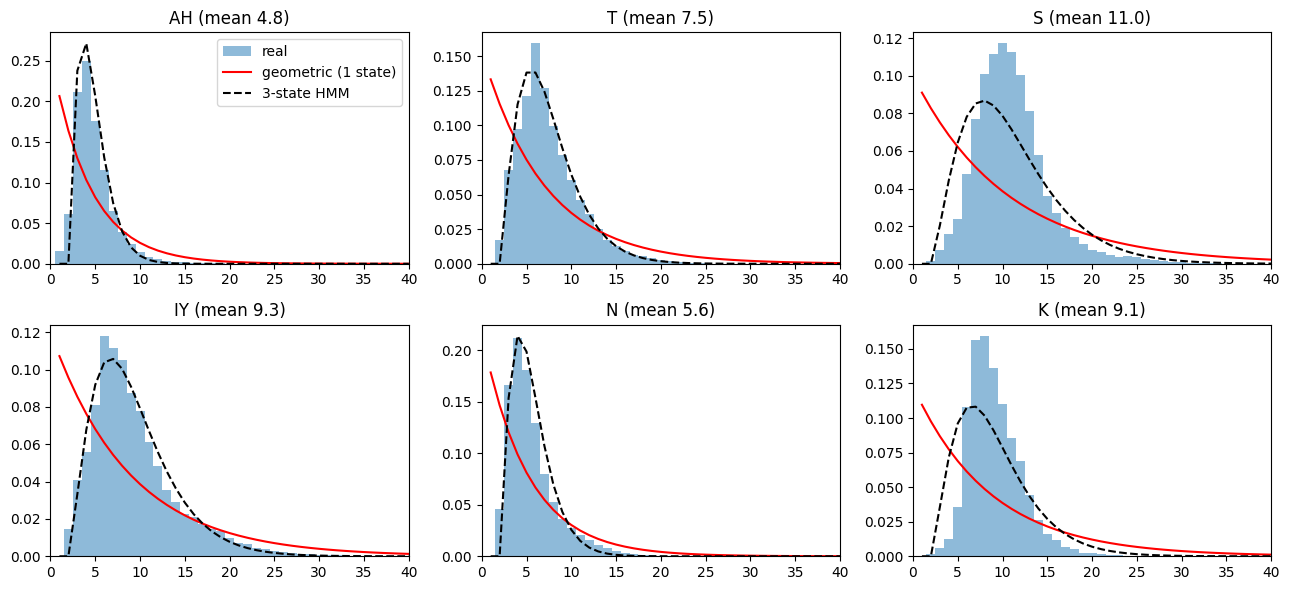

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(13, 6))
for ax, p in zip(axs.ravel(), ['AH', 'T', 'S', 'IY', 'N', 'K']):
    d = sp.loc[sp.base == p, 'dur_f'].clip(lower=1).values; m = d.mean(); x = np.arange(1, 41)
    ax.hist(d, bins=np.arange(0.5, 41.5), density=True, alpha=.5, label='real')
    ax.plot(x, geom.pmf(x, 1 / m), 'r-', label='geometric (1 state)')
    ax.plot(x, np.where(x >= 3, nbinom.pmf(np.maximum(x - 3, 0), 3, min(3 / m, .999)), 0), 'k--', label='3-state HMM')
    ax.set_title(f'{p} (mean {m:.1f})'); ax.set_xlim(0, 40)
axs[0, 0].legend(); plt.tight_layout(); plt.savefig(os.path.join(RESULTS, '04_hmm_vs_real.png'), dpi=150); plt.show()

**What to conclude:** compare the red and dashed curves to the histogram. Where is the real distribution narrower or shifted? A fixed-shape HMM duration model cannot adapt its shape to context; a learned predictor can. Note the honest caveat: MFA's *own* durations come from this very model, so real "ground truth" here already contains its bias (this is a limitation of using forced alignment as labels).

In [11]:
# ---- Outliers worth a look (very long speech phones)
thr = sp.dur_f.quantile(0.999)
out = sp[sp.dur_f > thr].groupby('base').size().sort_values(ascending=False).head(8)
print('99.9th percentile:', thr, 'frames; most common phones among outliers:\n', out)
json.dump({'n_utts': int(sp.utt_id.nunique()), 'n_phones': int(len(sp)), 'mean_frames': float(sp.dur_f.mean()),
           'median_frames': float(sp.dur_f.median()), 'p999_frames': float(thr)}, open(os.path.join(RESULTS, '04_eda_summary.json'), 'w'), indent=1)

99.9th percentile: 30.0 frames; most common phones among outliers:
 base
EY    134
AY     79
IY     66
S      64
OW     41
UW     37
CH     24
AW     24
dtype: int64
